# Optional Assignment — Urban Air Quality Time-Series Analysis

**Project question:** How does reference-measured nitrogen dioxide (NO₂) vary over time, and how accurately can simple baselines forecast its daily average?

We use the real **UCI Air Quality** dataset. UCI reports 9,358 hourly instances from a sensor deployment in an Italian city. The downloadable CSV contains dates from 10 March 2004 through 4 April 2005 and trailing empty rows that are removed during cleaning. It includes reference-analyzer pollutant concentrations, five metal-oxide sensor readings, and meteorological variables. The target is `NO2(GT)`, reference-measured nitrogen dioxide in µg/m³.

**Source:** [UCI Machine Learning Repository — Air Quality](https://archive.ics.uci.edu/dataset/360/air+quality) · DOI: 10.24432/C59K5F · Dataset citation: De Vito et al. (2008), *Sensors and Actuators B: Chemical*.

> UCI marks `-200` as missing and states the dataset is for research use; this notebook preserves the source and use conditions. The data is downloaded from UCI at runtime rather than copied into this repository.

## 1. Download and inspect the original data

The source file is a ZIP archive containing a semicolon-delimited CSV with comma decimal marks. The code below handles those format details and prints the observed date range and missing-value counts.

In [6]:
from io import BytesIO
from urllib.request import urlopen
from zipfile import ZipFile

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

DATA_URL = 'https://archive.ics.uci.edu/static/public/360/air+quality.zip'
with urlopen(DATA_URL, timeout=60) as response:
    archive_bytes = response.read()

with ZipFile(BytesIO(archive_bytes)) as archive:
    csv_name = next(name for name in archive.namelist() if name.endswith('AirQualityUCI.csv'))
    raw = pd.read_csv(archive.open(csv_name), sep=';', decimal=',')

raw.columns = raw.columns.str.strip()
raw = raw.dropna(axis=1, how='all')  # Remove empty trailing columns.
raw = raw.dropna(subset=['Date', 'Time']).copy()  # Remove fully blank records in the source CSV.
print('Rows and columns:', raw.shape)
display(raw.head())

Rows and columns: (9357, 15)


,Date,Time,CO(GT),PT08.S1(CO),NMHC(GT),C6H6(GT),PT08.S2(NMHC),NOx(GT),PT08.S3(NOx),NO2(GT),PT08.S4(NO2),PT08.S5(O3),T,RH,AH
0,10/03/2004,18.00.00,2.6,1360.0,150.0,11.9,1046.0,166.0,1056.0,113.0,1692.0,1268.0,13.6,48.9,0.7578
1,10/03/2004,19.00.00,2.0,1292.0,112.0,9.4,955.0,103.0,1174.0,92.0,1559.0,972.0,13.3,47.7,0.7255
2,10/03/2004,20.00.00,2.2,1402.0,88.0,9.0,939.0,131.0,1140.0,114.0,1555.0,1074.0,11.9,54.0,0.7502
3,10/03/2004,21.00.00,2.2,1376.0,80.0,9.2,948.0,172.0,1092.0,122.0,1584.0,1203.0,11.0,60.0,0.7867
4,10/03/2004,22.00.00,1.6,1272.0,51.0,6.5,836.0,131.0,1205.0,116.0,1490.0,1110.0,11.2,59.6,0.7888


## 2. Clean timestamps and missing readings

The source uses `DD/MM/YYYY` dates and times such as `18.00.00`. Adding the time components as a duration also handles `24.00.00` by rolling it into the next date. Duplicate timestamps, if present, are combined by their numeric mean. The sentinel `-200` is converted to missing before analysis.

In [7]:
date = pd.to_datetime(raw['Date'].astype(str).str.strip(), format='%d/%m/%Y', errors='coerce')
time_parts = raw['Time'].astype(str).str.strip().str.split('.', expand=True)
hours = pd.to_numeric(time_parts[0], errors='coerce').fillna(0)
minutes = pd.to_numeric(time_parts[1], errors='coerce').fillna(0)
seconds = pd.to_numeric(time_parts[2], errors='coerce').fillna(0)
timestamp = date + pd.to_timedelta(hours, unit='h') + pd.to_timedelta(minutes, unit='m') + pd.to_timedelta(seconds, unit='s')

data = raw.drop(columns=['Date', 'Time']).copy()
for column in data.columns:
    data[column] = pd.to_numeric(data[column], errors='coerce').replace(-200, np.nan)
data['timestamp'] = timestamp
data = (data.dropna(subset=['timestamp'])
            .groupby('timestamp').mean(numeric_only=True).sort_index())

target = 'NO2(GT)'
if target not in data.columns:
    raise KeyError(f'Missing expected target column: {target}')

hourly_no2 = data[target].asfreq('h')
print(f'Time range: {data.index.min()} to {data.index.max()}')
print(f'Hourly rows after timestamp cleanup: {len(hourly_no2):,}')
print(f'Missing NO₂ hours: {hourly_no2.isna().sum():,} ({hourly_no2.isna().mean():.1%})')
display(data.isna().mean().sort_values(ascending=False).rename('missing_fraction').to_frame().head(10))

Time range: 2004-03-10 18:00:00 to 2005-04-04 14:00:00
Hourly rows after timestamp cleanup: 9,357
Missing NO₂ hours: 1,642 (17.5%)


,missing_fraction
NMHC(GT),0.902319
CO(GT),0.179865
NO2(GT),0.175484
NOx(GT),0.175163
PT08.S1(CO),0.039115
C6H6(GT),0.039115
PT08.S2(NMHC),0.039115
PT08.S3(NOx),0.039115
PT08.S4(NO2),0.039115
PT08.S5(O3),0.039115


## 3. Explore the signal and data gaps

First inspect the hourly reference readings. The rolling mean highlights slower changes; the missingness plot makes clear why uninterrupted sensor records cannot be assumed.

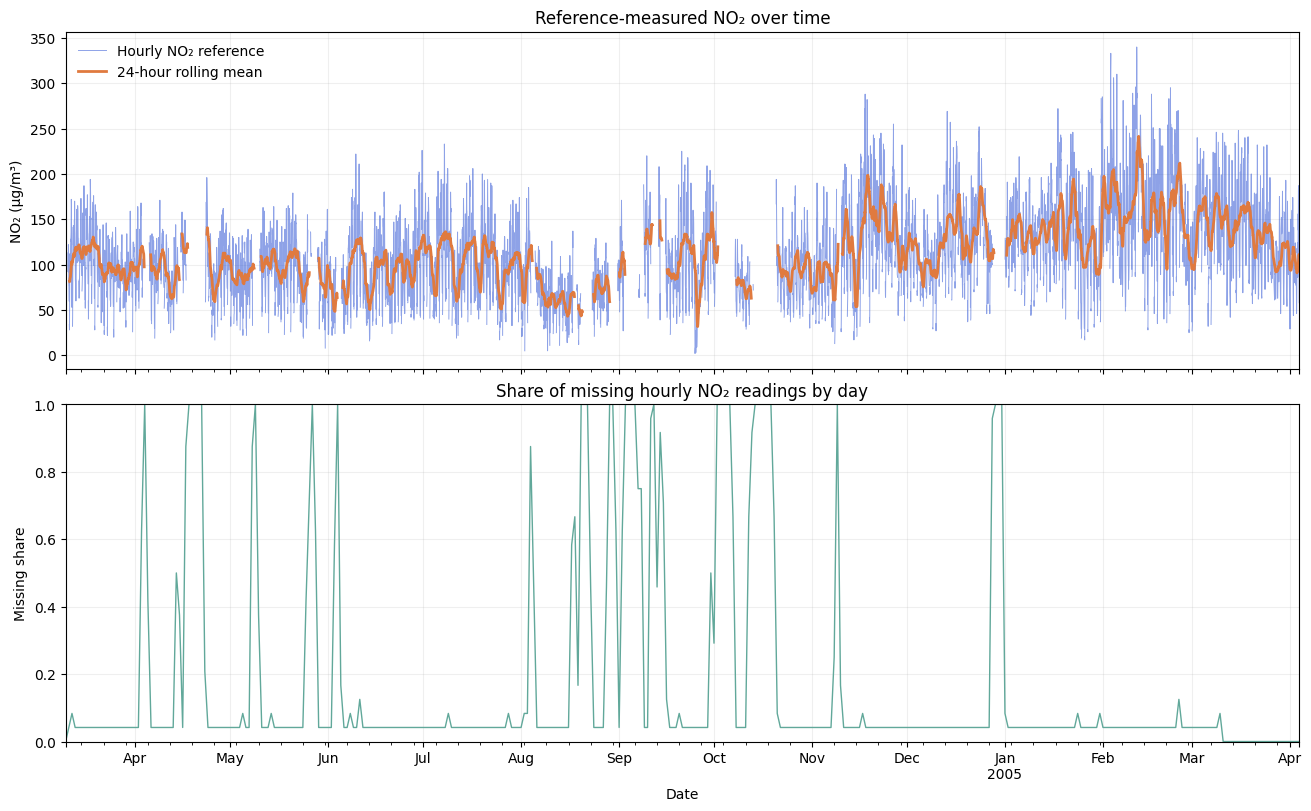

In [8]:
fig, axes = plt.subplots(2, 1, figsize=(13, 8), sharex=True, constrained_layout=True)
hourly_no2.plot(ax=axes[0], color='#3157d5', alpha=.55, lw=.7, label='Hourly NO₂ reference')
hourly_no2.rolling(24, min_periods=12).mean().plot(ax=axes[0], color='#e07a3f', lw=2, label='24-hour rolling mean')
axes[0].set(title='Reference-measured NO₂ over time', ylabel='NO₂ (µg/m³)')
axes[0].legend(frameon=False); axes[0].grid(alpha=.2)
hourly_no2.isna().astype(int).resample('D').mean().plot(ax=axes[1], color='#61a89a', lw=1)
axes[1].set(title='Share of missing hourly NO₂ readings by day', ylabel='Missing share', xlabel='Date', ylim=(0, 1))
axes[1].grid(alpha=.2); plt.show()

## 3A. Daily patterns and pollutant relationships

Hourly profiles can reveal recurring within-day structure, while pollutant correlations describe co-movement (not causation). Monthly comparisons are descriptive only: this record covers about 13 months, so it is too short for strong annual-seasonality claims.


,mean,median,count
Hour of day,,,
0,103.3,100.0,336
1,90.5,83.0,334
2,75.4,69.5,332
3,80.1,79.5,26
4,58.6,55.0,332
5,59.6,57.0,333
6,71.7,68.0,334
7,94.7,95.0,334
8,121.3,118.5,328


,mean,median,count
Day of week,,,
Monday,110.3,105.0,1122
Tuesday,117.4,115.0,1063
Wednesday,120.0,117.0,1068
Thursday,120.8,116.0,1121
Friday,123.5,119.0,1146
Saturday,107.6,101.0,1110
Sunday,91.7,85.0,1085


,mean,median,count
Month,,,
2004-03,102.6,101.0,488
2004-04,96.9,96.0,486
2004-05,93.1,96.0,598
2004-06,94.1,93.0,648
2004-07,104.1,104.0,711
2004-08,70.1,68.0,501
2004-09,108.0,107.0,444
2004-10,89.8,88.0,387
2004-11,122.5,118.0,658


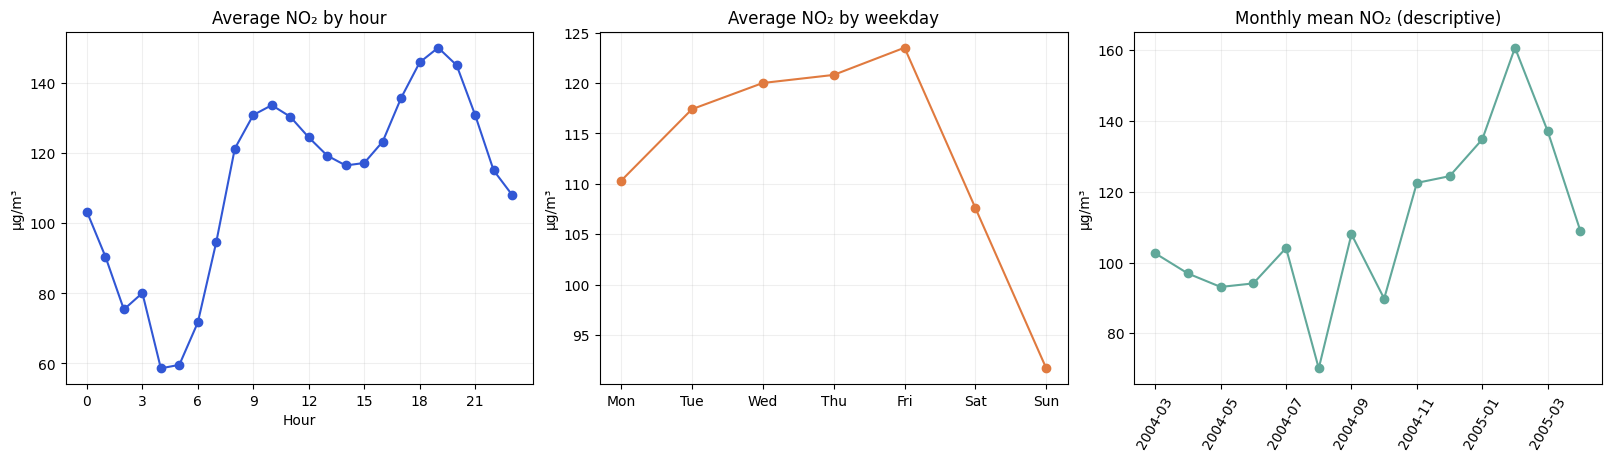

,NO2(GT),NOx(GT),CO(GT),C6H6(GT),T,RH,AH
NO2(GT),1.000000,0.760000,0.680000,0.610000,-0.190000,-0.090000,-0.340000
NOx(GT),0.760000,1.000000,0.800000,0.720000,-0.270000,0.220000,-0.150000
CO(GT),0.680000,0.800000,1.000000,0.930000,0.020000,0.050000,0.050000
C6H6(GT),0.610000,0.720000,0.930000,1.000000,0.200000,-0.060000,0.170000
T,-0.190000,-0.270000,0.020000,0.200000,1.000000,-0.580000,0.660000
RH,-0.090000,0.220000,0.050000,-0.060000,-0.580000,1.000000,0.170000
AH,-0.340000,-0.150000,0.050000,0.170000,0.660000,0.170000,1.000000


,NO2(GT),NOx(GT),CO(GT),C6H6(GT),T,RH,AH
NO2(GT),7715,7715,7258,7393,7393,7393,7393
NOx(GT),7715,7718,7261,7396,7396,7396,7396
CO(GT),7258,7261,7674,7344,7344,7344,7344
C6H6(GT),7393,7396,7344,8991,8991,8991,8991
T,7393,7396,7344,8991,8991,8991,8991
RH,7393,7396,7344,8991,8991,8991,8991
AH,7393,7396,7344,8991,8991,8991,8991


AttributeError: 'NoneType' object has no attribute 'style'

In [9]:
# Descriptive profiles use available valid observations; counts expose uneven coverage.
profile = data.copy()
profile['hour'] = profile.index.hour
profile['weekday'] = profile.index.day_name()
profile['month'] = profile.index.to_period('M').astype(str)

hour_profile = profile.groupby('hour')['NO2(GT)'].agg(['mean', 'median', 'count']).round(1)
weekday_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
weekday_profile = profile.groupby('weekday')['NO2(GT)'].agg(['mean', 'median', 'count']).reindex(weekday_order).round(1)
month_profile = profile.groupby('month')['NO2(GT)'].agg(['mean', 'median', 'count']).round(1)
display(hour_profile.rename_axis('Hour of day'))
display(weekday_profile.rename_axis('Day of week'))
display(month_profile.rename_axis('Month'))

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), constrained_layout=True)
hour_profile['mean'].plot(ax=axes[0], marker='o', color='#3157d5')
axes[0].set(title='Average NO₂ by hour', xlabel='Hour', ylabel='µg/m³', xticks=range(0, 24, 3))
weekday_profile['mean'].plot(ax=axes[1], marker='o', color='#e07a3f')
axes[1].set(title='Average NO₂ by weekday', xlabel='', ylabel='µg/m³', xticks=range(7), xticklabels=['Mon','Tue','Wed','Thu','Fri','Sat','Sun'])
month_profile['mean'].plot(ax=axes[2], marker='o', color='#61a89a')
axes[2].set(title='Monthly mean NO₂ (descriptive)', xlabel='', ylabel='µg/m³'); axes[2].tick_params(axis='x', rotation=60)
for ax in axes: ax.grid(alpha=.2)
plt.show()

# Pairwise-complete correlations and support counts; associations are not causal effects.
corr_cols = ['NO2(GT)', 'NOx(GT)', 'CO(GT)', 'C6H6(GT)', 'T', 'RH', 'AH']
display(data[corr_cols].corr(min_periods=100).round(2).style.background_gradient(cmap='RdBu_r', vmin=-1, vmax=1))
display(data[corr_cols].notna().astype(int).T @ data[corr_cols].notna().astype(int)).style.format('{:,.0f}')

valid_daily = daily_no2.dropna() if 'daily_no2' in globals() else hourly_no2.resample('D').mean().dropna()
trend_x = np.arange(len(valid_daily))
trend_slope = np.polyfit(trend_x, valid_daily.to_numpy(), 1)[0]
print(f'Descriptive linear slope across observed daily means: {trend_slope:.2f} µg/m³ per observed day ({trend_slope * 30:.1f} per 30 observed days). This is not a causal or seasonally adjusted trend.')


## 4. Build a daily forecasting series

Daily mean NO₂ is used for a compact one-month forecasting exercise. We keep the original gaps: daily means with no valid hourly readings remain missing. The final 30 calendar days form the test period, and only observed daily targets are scored.

Daily series: 2004-03-10 to 2005-04-04
Training observations: 327 | Observed test days: 30 of 30


,NO₂ (µg/m³)
count,357.00
mean,111.91
std,32.46
min,38.04
25%,89.95
50%,109.22
75%,131.22
max,223.35


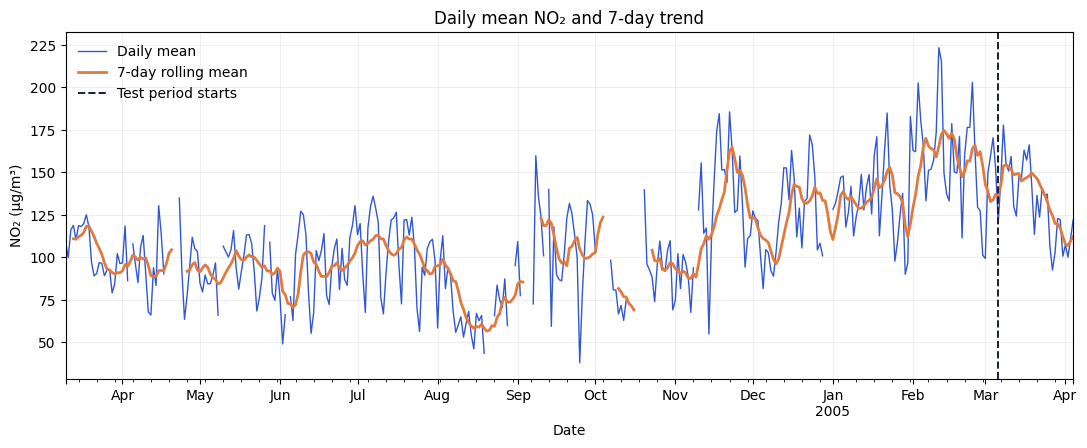

In [ ]:
daily_no2 = hourly_no2.resample('D').mean()
last_date = daily_no2.index.max().normalize()
test_start = last_date - pd.Timedelta(days=29)
train = daily_no2.loc[daily_no2.index < test_start].dropna()
test = daily_no2.loc[(daily_no2.index >= test_start) & daily_no2.notna()]

print(f'Daily series: {daily_no2.index.min().date()} to {daily_no2.index.max().date()}')
print(f'Training observations: {len(train):,} | Observed test days: {len(test):,} of 30')
display(daily_no2.describe().rename('NO₂ (µg/m³)').to_frame().round(2))

fig, ax = plt.subplots(figsize=(13, 4.5))
daily_no2.plot(ax=ax, color='#3157d5', lw=1, label='Daily mean')
daily_no2.rolling(7, min_periods=4).mean().plot(ax=ax, color='#e07a3f', lw=2, label='7-day rolling mean')
ax.axvline(test_start, color='#172033', ls='--', lw=1.4, label='Test period starts')
ax.set(title='Daily mean NO₂ and 7-day trend', ylabel='NO₂ (µg/m³)', xlabel='Date')
ax.legend(frameon=False); ax.grid(alpha=.2); plt.show()

## 5. Compare chronological forecast baselines

We compare a last-observation forecast, a day-of-week seasonal profile learned from the training period, and a linear trend. Each forecast covers the same 30-calendar-day horizon. No test values are used to fit any baseline. The symmetric MAPE remains defined when observed values are zero.

,Scored days,MAE,RMSE,sMAPE (%)
Linear trend,30.0,20.84,24.98,15.76
Last observed value,30.0,24.40,29.61,18.10
Training weekday mean,30.0,25.88,30.06,20.70


C:\Users\nvh89\AppData\Local\Temp\ipykernel_6448\3492296815.py:30: UserWarning: This axis already has a converter set and is updating to a potentially incompatible converter
  ax.plot(prediction.index, prediction, marker='.', lw=1.7, label=name)


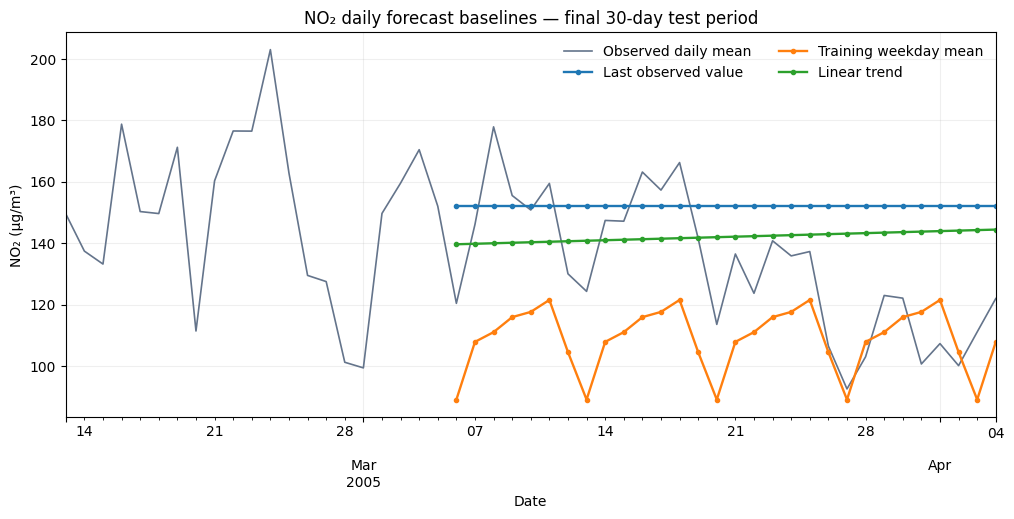

In [10]:
test_dates = test.index
last_value = train.iloc[-1]
weekday_profile = train.groupby(train.index.dayofweek).mean()
weekday_forecast = pd.Series([weekday_profile.get(day, train.mean()) for day in test_dates.dayofweek], index=test_dates)

x_train = (train.index - train.index.min()).total_seconds() / 86400
x_test = (test_dates - train.index.min()).total_seconds() / 86400
slope, intercept = np.polyfit(x_train, train.to_numpy(), 1)

forecasts = {
    'Last observed value': pd.Series(last_value, index=test_dates),
    'Training weekday mean': weekday_forecast,
    'Linear trend': pd.Series(slope * x_test + intercept, index=test_dates),
}

def score_forecast(actual, predicted):
    paired = pd.concat([actual.rename('actual'), predicted.rename('predicted')], axis=1).dropna()
    error = paired['actual'] - paired['predicted']
    denominator = paired['actual'].abs() + paired['predicted'].abs()
    smape = (200 * error.abs() / denominator.replace(0, np.nan)).mean()
    return {'Scored days': len(paired), 'MAE': error.abs().mean(),
            'RMSE': np.sqrt((error ** 2).mean()), 'sMAPE (%)': smape}

scores = pd.DataFrame({name: score_forecast(test, pred) for name, pred in forecasts.items()}).T
display(scores.sort_values('MAE').round(2))

fig, ax = plt.subplots(figsize=(12, 5))
daily_no2.loc[test_start - pd.Timedelta(days=21):].plot(ax=ax, color='#64748b', lw=1.2, label='Observed daily mean')
for name, prediction in forecasts.items():
    ax.plot(prediction.index, prediction, marker='.', lw=1.7, label=name)
ax.set(title='NO₂ daily forecast baselines — final 30-day test period', ylabel='NO₂ (µg/m³)', xlabel='Date')
ax.legend(frameon=False, ncol=2); ax.grid(alpha=.2); plt.show()

## 6. Rolling-origin forecast experiment

**Question:** does the linear trend consistently outperform simple persistence and weekday-average baselines across multiple historical forecast origins, or was the final-month score unusually favorable? This experiment uses expanding training windows and 14-day horizons. Each fold is evaluated only on observed target days; each model is refit using data available at that origin.


,fold,origin,model,n_scored,MAE,RMSE,sMAPE_pct
0,1,2004-09-05,Last observed value,12,32.62,40.52,32.67
1,1,2004-09-05,Training weekday mean,12,27.16,31.56,26.57
2,1,2004-09-05,Linear trend,12,29.61,37.23,29.08
3,2,2004-10-03,Last observed value,7,28.29,30.28,31.94
4,2,2004-10-03,Training weekday mean,7,18.11,22.25,21.11
5,2,2004-10-03,Linear trend,7,17.58,19.25,21.41
6,3,2004-10-31,Last observed value,13,31.56,38.86,34.80
7,3,2004-10-31,Training weekday mean,13,15.54,21.55,15.65
8,3,2004-10-31,Linear trend,13,20.77,26.76,21.46
9,4,2004-11-28,Last observed value,14,17.33,20.53,16.48


,folds,scored_days,mean_MAE,sd_MAE,mean_RMSE,mean_sMAPE_pct
model,,,,,,
Linear trend,8,99,22.92,6.91,27.41,20.04
Training weekday mean,8,99,25.39,11.69,30.41,22.36
Last observed value,8,99,27.37,8.69,31.99,24.92


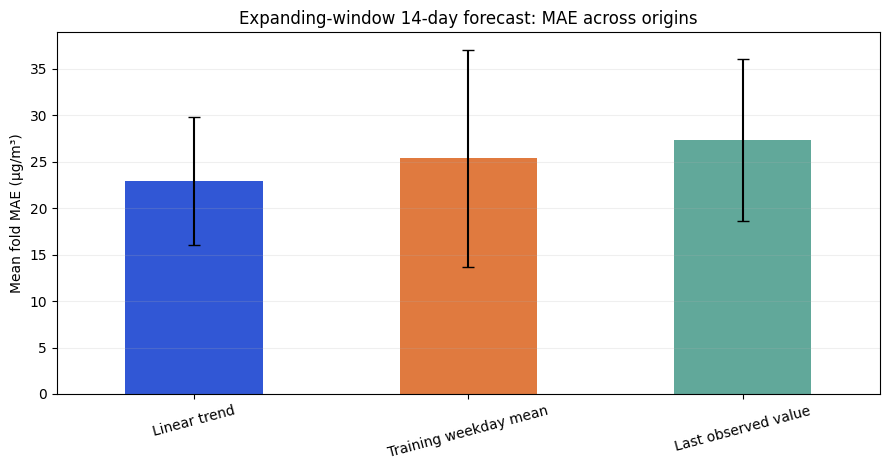

Caption: Linear trend has the lowest mean MAE (22.92 µg/m³) across 8 rolling origins, 9.7% lower than Training weekday mean. Error bars show fold-to-fold MAE standard deviation; prefer this multi-origin comparison to a conclusion based only on one final holdout.


In [11]:
horizon_days = 14
step_days = 28
initial_days = 180
origin_dates = pd.date_range(daily_no2.index.min() + pd.Timedelta(days=initial_days - 1), daily_no2.index.max() - pd.Timedelta(days=horizon_days), freq=f'{step_days}D')
rolling_rows = []

for fold, origin in enumerate(origin_dates, start=1):
    history = daily_no2.loc[:origin].dropna()
    future_dates = pd.date_range(origin + pd.Timedelta(days=1), periods=horizon_days, freq='D')
    actual = daily_no2.reindex(future_dates).dropna()
    if len(history) < 100 or actual.empty: continue

    train_x = (history.index - history.index.min()).total_seconds() / 86400
    future_x = (actual.index - history.index.min()).total_seconds() / 86400
    slope, intercept = np.polyfit(train_x, history.to_numpy(), 1)
    weekday_profile = history.groupby(history.index.dayofweek).mean()
    predictions = {
        'Last observed value': np.repeat(history.iloc[-1], len(actual)),
        'Training weekday mean': np.array([weekday_profile.get(day, history.mean()) for day in actual.index.dayofweek]),
        'Linear trend': slope * future_x + intercept,
    }
    for model_name, values in predictions.items():
        error = actual.to_numpy() - values
        denom = np.abs(actual.to_numpy()) + np.abs(values)
        smape = np.mean(np.divide(2 * np.abs(error), denom, out=np.zeros_like(error, dtype=float), where=denom != 0)) * 100
        rolling_rows.append({'fold': fold, 'origin': origin.date(), 'model': model_name, 'n_scored': len(actual), 'MAE': np.mean(np.abs(error)), 'RMSE': np.sqrt(np.mean(error ** 2)), 'sMAPE_pct': smape})

rolling_scores = pd.DataFrame(rolling_rows)
rolling_summary = rolling_scores.groupby('model').agg(folds=('fold', 'nunique'), scored_days=('n_scored', 'sum'), mean_MAE=('MAE', 'mean'), sd_MAE=('MAE', 'std'), mean_RMSE=('RMSE', 'mean'), mean_sMAPE_pct=('sMAPE_pct', 'mean')).sort_values('mean_MAE')
display(rolling_scores.round(2))
display(rolling_summary.round(2))

fig, ax = plt.subplots(figsize=(9, 4.8))
rolling_summary['mean_MAE'].sort_values().plot(kind='bar', yerr=rolling_summary.loc[rolling_summary['mean_MAE'].sort_values().index, 'sd_MAE'].fillna(0), capsize=4, ax=ax, color=['#3157d5', '#e07a3f', '#61a89a'])
ax.set(title='Expanding-window 14-day forecast: MAE across origins', xlabel='', ylabel='Mean fold MAE (µg/m³)'); ax.tick_params(axis='x', rotation=15); ax.grid(axis='y', alpha=.2)
plt.tight_layout(); plt.show()

winner = rolling_summary['mean_MAE'].idxmin()
ranked_mae = rolling_summary['mean_MAE'].sort_values()
if len(ranked_mae) > 1:
    runner_up = ranked_mae.index[1]
    improvement = (ranked_mae.iloc[1] - ranked_mae.iloc[0]) / ranked_mae.iloc[1] * 100
    n_folds = int(rolling_summary.loc[winner].iloc[0])
    print(f'Caption: {winner} has the lowest mean MAE ({ranked_mae.iloc[0]:.2f} µg/m³) across {n_folds} rolling origins, {improvement:.1f}% lower than {runner_up}. Error bars show fold-to-fold MAE standard deviation; prefer this multi-origin comparison to a conclusion based only on one final holdout.')


## 6. Interpretation and limitations

Using the downloaded source CSV and the exact cleaning and split above, the linear-trend baseline gives MAE 20.84, RMSE 24.98, and sMAPE 15.76% on the final 30 days. The last-value baseline gives MAE 24.40; the training weekday mean gives MAE 25.88. MAE and RMSE are in micrograms per cubic metre. Run the scoring cell to reproduce the full comparison.

The score table identifies the best of these simple baselines for this period. The plots and missingness summary should inform how much confidence to place in that ranking.

- This is a single sensor deployment in one Italian city, not a representative national air-quality sample.
- The series spans roughly one year, so it cannot establish robust annual seasonality.
- `-200` is a source sentinel for missing data; missing sensor readings may be systematic. We do not fill gaps for model fitting or test scoring.
- The target is reference-analyzer NO₂. Sensor columns are not treated as future-known predictors in this baseline forecast.
- A stronger follow-up could use rolling-origin validation, uncertainty intervals, and a model that incorporates weather and co-pollutants.

### Reproducibility

Run cells from top to bottom in Colab or Jupyter. The notebook downloads the original UCI ZIP at runtime and uses only pandas, NumPy, and Matplotlib beyond the standard library.